## Categorização de Nível de Toxicidade de Comentários do Reddit

### Coleta do Dataset

A lógica já foi estabelecida anteriormente. Estamos fazendo a coleta utilizando API dada, dos dados fornecidos em três diferentes comunidades (shitpostbr, FariaLimaBets, brasilivre). Fizemos a coleta de TODOS possíveis dados. Adotamos uma estratégia de coleta pausada, para respeitar os limites relacionados tanto ao google colab quanto do Reddit.

In [ ]:
#Instalação das bibliotecas necessárias para o pré processamento dos dados e a conexão com o reddit.
!pip install praw pandas
!pip install faiss-cpu

  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [praw]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 109.4 MB/s  0:00:00


In [ ]:
import os
import json
import time
import praw
import pandas as pd
from datetime import datetime
from prawcore.exceptions import TooManyRequests
from google.colab import drive
import numpy as np
import faiss
import networkx as nx
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
import pickle

#importação das bibliotecas necessárias para o código
#praw é o que permite a conexão com os servidores do reddit para coleta de dados
#pandas serve para análise dos dados
#faiss ferramenta do facebook que auxilia no cálculo das distâncias matemáticas entre os textos
#networkx para realizar a construção dos grafos



In [ ]:
#monta o drive e define os caminhos para salvar a base de dados

from google.colab import drive
drive.mount('/content/drive')

caminho_checkpoint = '/content/drive/MyDrive/dataset_reddit_checkpoint.json'
caminho_final = '/content/drive/MyDrive/dataset_reddit_final.json'
caminho_status = '/content/drive/MyDrive/dataset_reddit_status.json'
caminho_secret = '/content/drive/MyDrive/secretReddit.json'
caminho_emolex = '/content/drive/MyDrive/emolex/Portuguese-NRC-EmoLex.txt'

with open(caminho_secret, 'r', encoding='utf-8') as f:
    chaves = json.load(f)

reddit = praw.Reddit(
    client_id=chaves['client_id'],
    client_secret=chaves['client_secret'],
    user_agent=chaves['user_agent']
)


#definição dos pontos de checagem do dataset final e os checkpoints

Mounted at /content/drive


In [ ]:
#definição dos subreddits alvos
subreddits_alvo = ['shitpostbr', 'FariaLimaBets', 'brasilivre', 'BrasildoB', 'botecodoreddit']

In [ ]:
#definindo limite para a coleta dos dados, considerando tanto o google colab quanto o reddit
TEMPO_LIMITE_HORAS = 4.0
TEMPO_LIMITE_SEGUNDOS = TEMPO_LIMITE_HORAS * 3600
INTERVALO_CHECKPOINT_SEGUNDOS = 120 #faz o salvamento no drive no máximo a cada 2min
POSTS_ENTRE_CHECKPOINT = 10
REPLACE_MORE_LIMIT = None

In [ ]:
inicio_execucao = time.time()

class TempoExcedidoError(Exception):
    pass

#função para realizar a extração dos dados e organiza-los em formato de dicionário
def extrair_dados(item, is_post=False, sub_name=""):
    try:
        author = item.author.name if item.author else "[Deletado/Anonimo]"
    except AttributeError:
        author = "[Erro ao extrair]"

    if is_post:
        return {
            'subreddit': sub_name,
            'post_id': item.id,
            'comment_id': item.id,
            'parent_id': 'root',
            'author': author,
            'text': item.title + " " + (item.selftext if item.selftext else ""),
            'score': item.score,
            'timestamp': datetime.fromtimestamp(item.created_utc).strftime('%Y-%m-%d %H:%M:%S'),
            'type': 'post'
        }
    else:
        return {
            'subreddit': sub_name,
            'post_id': item.submission.id,
            'comment_id': item.id,
            'parent_id': item.parent_id.split('_')[1] if '_' in item.parent_id else item.parent_id,
            'author': author,
            'text': item.body,
            'score': item.score,
            'timestamp': datetime.fromtimestamp(item.created_utc).strftime('%Y-%m-%d %H:%M:%S'),
            'type': 'comment'
        }


def carregar_status():
    if os.path.exists(caminho_status):
        with open(caminho_status, 'r', encoding='utf-8') as f:
            return json.load(f)
    return {'subs_finalizados': []}


def salvar_status(status):
    with open(caminho_status, 'w', encoding='utf-8') as f:
        json.dump(status, f, ensure_ascii=False, indent=2)


def salvar_checkpoint(dados):
    pd.DataFrame(dados).to_csv(caminho_checkpoint, index=False, encoding='utf-8')


def tempo_esgotado():
    return (time.time() - inicio_execucao) > TEMPO_LIMITE_SEGUNDOS


#Reinicialização de onde foi interrompido - Verifica a existencia de um dado checkpoint e continua a partir dali''''

dados_gerais = []
posts_processados = set()

if os.path.exists(caminho_checkpoint):
    print("Checkpoint encontrado no Drive! Carregando dados anteriores...")
    df_existente = pd.read_csv(caminho_checkpoint)
    dados_gerais = df_existente.to_dict('records')
    ids_salvos = df_existente[df_existente['type'] == 'post']['post_id'].unique()
    posts_processados.update(ids_salvos)
    print(f" Retomando coleta. {len(posts_processados)} posts já estão salvos e serão ignorados.")
else:
    print("Nenhum checkpoint encontrado no Drive. Iniciando coleta do zero.")

status = carregar_status()
subs_finalizados = set(status.get('subs_finalizados', []))
if subs_finalizados:
    print(f" Subreddits já finalizados em execuções anteriores (serão pulados): {sorted(subs_finalizados)}")


#Parte responsável pela coleta dos dados, loop de navegar dentro dos subrredits e salvar os dados de acordo com as funções predefinidas'''

ultimo_checkpoint_tempo = time.time()
posts_desde_ultimo_checkpoint = 0

try:
    for sub_name in subreddits_alvo:

        if sub_name in subs_finalizados:
            print(f"⏭️  r/{sub_name} já foi totalmente coletado antes. Pulando.")
            continue

        print(f"\n####### Iniciando coleta no r/{sub_name} #######")

        # Enquanto o subreddit não for concluído com sucesso, tentamos de novo (ex.: após um rate limit) sem pular para o próximo subreddit da lista,
        subreddit_concluido = False

        while not subreddit_concluido:
            try:
                subreddit = reddit.subreddit(sub_name)

                # listagens da API do Reddit (top/hot/new/etc.)
                # são limitadas a ~1000 itens pela própria plataforma, mesmo com
                # limit=None. Ou seja, "all" aqui não é literalmente "todo o histórico".
                for submission in subreddit.top(time_filter='all', limit=None):

                    if submission.id in posts_processados:
                        continue

                    if tempo_esgotado():
                        raise TempoExcedidoError()

                    try:
                        post_data = extrair_dados(submission, is_post=True, sub_name=sub_name)
                        submission.comments.replace_more(limit=REPLACE_MORE_LIMIT)
                        comentarios_data = [
                            extrair_dados(c, is_post=False, sub_name=sub_name)
                            for c in submission.comments.list()
                        ]
                    except TooManyRequests:
                        # Propaga para o except externo: o post NÃO é marcado como
                        # processado, então na retomada ele é refeito por completo —
                        # evita salvar um post "órfão" sem os comentários.
                        raise
                    except Exception as e_post:
                        print(f"Falha ao processar post {submission.id}: {e_post}. Pulando este post.")
                        posts_processados.add(submission.id)  # evita loop infinito num post problemático
                        continue

                    # Só grava e marca como processado se post + comentários vieram OK
                    dados_gerais.append(post_data)
                    dados_gerais.extend(comentarios_data)
                    posts_processados.add(submission.id)
                    posts_desde_ultimo_checkpoint += 1

                    # Checkpoint por contagem  (10)OU por tempo, o que vier primeiro
                    tempo_desde_checkpoint = time.time() - ultimo_checkpoint_tempo
                    if (posts_desde_ultimo_checkpoint >= POSTS_ENTRE_CHECKPOINT
                            or tempo_desde_checkpoint >= INTERVALO_CHECKPOINT_SEGUNDOS):
                        print(f"Salvando checkpoint... ({len(posts_processados)} posts no total)")
                        salvar_checkpoint(dados_gerais)
                        ultimo_checkpoint_tempo = time.time()
                        posts_desde_ultimo_checkpoint = 0

                    time.sleep(1.5)

                # Se o for terminou sem exceção, o subreddit foi coberto por completo
                subreddit_concluido = True
                subs_finalizados.add(sub_name)
                salvar_status({'subs_finalizados': sorted(subs_finalizados)})
                print(f"✅ r/{sub_name} finalizado e marcado como concluído.")

            except TooManyRequests:
                print(" Limite de requisições. Salvando progresso e pausando por 15 minutos...")
                salvar_checkpoint(dados_gerais)
                time.sleep(900)
                # subreddit_concluido continua False -> o while retenta o MESMO
                # subreddit, e os posts já salvos são pulados automaticamente.

except TempoExcedidoError:
    print(f"\n Orçamento de tempo ({TEMPO_LIMITE_HORAS}h) atingido. Salvando progresso e encerrando "
          f"esta execução com segurança. Rode a célula novamente para continuar de onde parou.")

except Exception as e:
    print(f"\nErro não previsto: {e}. Salvando progresso antes de encerrar.")

finally:
    salvar_checkpoint(dados_gerais)
    salvar_status({'subs_finalizados': sorted(subs_finalizados)})


#Salvamento Final dos daods

df_final = pd.DataFrame(dados_gerais)
df_final.to_csv(caminho_final, index=False, encoding='utf-8')
print(f"\n Execução encerrada. Total de registros salvos até agora: {len(df_final)}")

if set(subreddits_alvo) <= subs_finalizados:
    print("🎉 Todos os subreddits alvo foram coletados por completo!")
else:
    faltando = set(subreddits_alvo) - subs_finalizados
    print(f"ℹ  Ainda faltam: {sorted(faltando)}. Rode a célula novamente para continuar.")

Checkpoint encontrado no Drive! Carregando dados anteriores...
 Retomando coleta. 998 posts já estão salvos e serão ignorados.
 Subreddits já finalizados em execuções anteriores (serão pulados): ['BrasildoB', 'FariaLimaBets', 'botecodoreddit', 'brasilivre', 'shitpostbr']
⏭️  r/shitpostbr já foi totalmente coletado antes. Pulando.
⏭️  r/FariaLimaBets já foi totalmente coletado antes. Pulando.
⏭️  r/brasilivre já foi totalmente coletado antes. Pulando.
⏭️  r/BrasildoB já foi totalmente coletado antes. Pulando.
⏭️  r/botecodoreddit já foi totalmente coletado antes. Pulando.

 Execução encerrada. Total de registros salvos até agora: 86950
🎉 Todos os subreddits alvo foram coletados por completo!


### Pré processamento dos dados coletados

Realizamos a limpeza das tabelas pois como todos os dados das comunidades são coletados, alguns comentários são vazios, deletados, duplicados e afins. Além disso, textos muito curtos são excluidos pois são irrelevantes para análise de contexto.

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd

# Caminhos compartilhados entre as partes (tudo persistido no Drive)
PASTA_DRIVE = '/content/drive/MyDrive'
caminho_dataset = f'{PASTA_DRIVE}/dataset_reddit_final.csv'        # gerado pela coleta
caminho_dataset_limpo = f'{PASTA_DRIVE}/dataset_reddit_limpo.csv'  # saída da Parte 1
caminho_embeddings = f'{PASTA_DRIVE}/embeddings.npy'                # saída da Parte 2
caminho_ids_embeddings = f'{PASTA_DRIVE}/embeddings_ids.csv'        # saída da Parte 2
caminho_grafo = f'{PASTA_DRIVE}/rede_similaridade.pkl'              # saída da Parte 3
caminho_clusters = f'{PASTA_DRIVE}/clusters.csv'                    # saída da Parte 4
caminho_topicos = f'{PASTA_DRIVE}/topicos_por_cluster.csv'          # saída da Parte 5


#Pré Processamento dos dados
print("Carregando dataset coletado...")
df = pd.read_csv(caminho_dataset)
antes = len(df)

# Remove linhas sem texto ou com texto vazio
df['text'] = df['text'].astype(str).str.strip()
df = df[df['text'].notna() & (df['text'] != '') & (df['text'].str.lower() != 'nan')]

# Remove conteúdo removido/deletado
df = df[~df['text'].str.lower().isin(['[removed]', '[deleted]', '[removido]', '[deletado]'])]

# Remove textos muito curtos (ex: "kkkk", "+1")
MIN_PALAVRAS = 3
df = df[df['text'].str.split().str.len() >= MIN_PALAVRAS]

# Remove duplicatas
df = df.drop_duplicates(subset='text')
df = df.drop_duplicates(subset='comment_id')  # comment_id é único por linha

print(f"{antes} linhas -> {len(df)} linhas após limpeza ({antes - len(df)} removidas).")
df.to_csv(caminho_dataset_limpo, index=False, encoding='utf-8')
print(f"💾 Dataset limpo salvo em: {caminho_dataset_limpo}")

Carregando dataset coletado...
263021 linhas -> 217288 linhas após limpeza (45733 removidas).
💾 Dataset limpo salvo em: /content/drive/MyDrive/dataset_reddit_limpo.csv


### Transformando o texto em embeddings

Agora utilizamos os modelos transformers para "ler" cada texto e transforma-los em um vetor (ou embeddings). Textos com assuntos semelhantes tem valores semelhantes atribuidos.

In [ ]:
from sentence_transformers import SentenceTransformer

#utilizamos o modelo 'paraphrase-multilingual-MiniLM-L12-v2' com aceitação multilingual para adequação ao pt-br
#o lote é definido como 128 textos por vez para não sobrecarregar a memória
NOME_MODELO = 'paraphrase-multilingual-MiniLM-L12-v2'
TAMANHO_LOTE = 128

print("Carregando dataset limpo")
df = pd.read_csv(caminho_dataset_limpo)

modelo = SentenceTransformer(NOME_MODELO)

print(f"Gerando embeddings para {len(df)} textos...")
embeddings = modelo.encode(
    df['text'].tolist(),
    batch_size=TAMANHO_LOTE,
    show_progress_bar=True,
    convert_to_numpy=True
)

np.save(caminho_embeddings, embeddings)
df[['comment_id', 'post_id', 'subreddit', 'type']].to_csv(caminho_ids_embeddings, index=False, encoding='utf-8')
print(f"Embeddings salvos em: {caminho_embeddings} (shape: {embeddings.shape})")
print(f"Mapeamento de IDs salvo em: {caminho_ids_embeddings}")

Carregando dataset limpo


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Gerando embeddings para 217288 textos...


Batches:   0%|          | 0/1698 [00:00<?, ?it/s]

Embeddings salvos em: /content/drive/MyDrive/embeddings.npy (shape: (217288, 384))
Mapeamento de IDs salvo em: /content/drive/MyDrive/embeddings_ids.csv


### Criando a rede de similaridade semântica

O código faz a comparação através dos embeddings de todos os textos. Caso a numeração deles seja próximo, ele cria uma linha (aresta) ligando os dois pontos (nós). O algoritmo procura somente os k (10) vizinhos mais próximos. O valor foi definido para evitar que comentários sem conexão fossem ligados uns aos outros.

In [ ]:
PASTA_DRIVE = '/content/drive/MyDrive'
caminho_embeddings = f'{PASTA_DRIVE}/embeddings.npy'
caminho_ids_embeddings = f'{PASTA_DRIVE}/embeddings_ids.csv'
caminho_grafo = f'{PASTA_DRIVE}/rede_similaridade.pkl'

if os.path.exists(caminho_grafo):
    print(f"Rede de similaridade já existe em {caminho_grafo}. Pulando Parte 3.")
else:
    import faiss
    import networkx as nx

    K_VIZINHOS = 10              # quantos vizinhos mais próximos buscar por texto
    LIMIAR_SIMILARIDADE = 0.75   # só vira aresta se cosseno >= esse valor

    print("Carregando embeddings (Parte 2)...")
    embeddings = np.load(caminho_embeddings).astype('float32')
    ids_df = pd.read_csv(caminho_ids_embeddings)
    comment_ids = ids_df['comment_id'].tolist()

    # Normaliza os vetores -> produto interno (IP) equivale a similaridade de cosseno
    faiss.normalize_L2(embeddings)

    print("Construindo índice FAISS e buscando vizinhos mais próximos...")
    indice = faiss.IndexFlatIP(embeddings.shape[1])
    indice.add(embeddings)

    # k+1 porque o vizinho mais próximo de cada texto é sempre ele mesmo
    similaridades, vizinhos = indice.search(embeddings, K_VIZINHOS + 1)

    print("Montando o grafo de similaridade...")
    G = nx.Graph()
    G.add_nodes_from(comment_ids)

    for i, id_origem in enumerate(comment_ids):
        for pos in range(1, K_VIZINHOS + 1):  # pula pos=0 (ele mesmo)
            j = int(vizinhos[i][pos])
            sim = float(similaridades[i][pos])
            if j == -1 or j == i or sim < LIMIAR_SIMILARIDADE:
                continue
            id_destino = comment_ids[j]
            if G.has_edge(id_origem, id_destino):
                G[id_origem][id_destino]['weight'] = max(G[id_origem][id_destino]['weight'], sim)
            else:
                G.add_edge(id_origem, id_destino, weight=sim)

    # Remove nós isolados (nenhum vizinho acima do limiar) para limpar a rede
    isolados = list(nx.isolates(G))
    G.remove_nodes_from(isolados)

    print(f" Rede construída: {G.number_of_nodes()} nós, {G.number_of_edges()} arestas "
          f"({len(isolados)} textos ficaram isolados e foram removidos).")

    with open(caminho_grafo, 'wb') as f:
        pickle.dump(G, f)
    print(f"Rede salva em: {caminho_grafo}")

Rede de similaridade já existe em /content/drive/MyDrive/rede_similaridade.pkl. Pulando Parte 3.


### Clusterização dos dados

Agora que os dados estão organizados em uma rede de similaridade, nós separamos esses dados em clusters. O algoritmo utilizado foi o Louvain, que analisa  rede e elimina as conexões entre dados que não tem uma semelhança tão suficiente ou ligação. Utilizamos como parametro 1.0 para o Louvain. Alterando para valores maiores criamos muitas ilhas pequenas, valores menores uma quantidade pequena de grandes ilhas.
Depois disso, utilizamos o BERTopic que avalia esses clusters e nomeia, baseado na repetição de termos (tokens).
CountVectorizer(min_df=5, max_df=0.85): Para ser uma palavra-chave do assunto, a palavra tem que aparecer em pelo menos 5 textos, mas não pode aparecer em mais de 85% de toda a base (se não é uma palavra genérica como "você", "mas", "que").

In [ ]:
import os
import pickle
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

PASTA_DRIVE = '/content/drive/MyDrive'
caminho_grafo = f'{PASTA_DRIVE}/rede_similaridade.pkl'
caminho_clusters = f'{PASTA_DRIVE}/clusters.csv'

if os.path.exists(caminho_clusters):
    print(f"Clusters já existem em {caminho_clusters}. Pulando Parte 4.")
else:
    import networkx as nx
    from networkx.algorithms.community import louvain_communities, modularity

    RESOLUCAO = 1.0  # >1 gera mais clusters (menores); <1 gera menos clusters (maiores)

    print("Carregando rede de similaridade (Parte 3)...")
    try:
        with open(caminho_grafo, 'rb') as f:
            G = pickle.load(f)
    except EOFError:
        print(f"ERRO: O arquivo '{caminho_grafo}' está vazio ou corrompido.")
        print("Por favor, execute novamente a célula anterior (Parte 3) para gerar a rede de similaridade.")
        raise FileNotFoundError(f"Rede de similaridade não pôde ser carregada de '{caminho_grafo}'. Reexecute a Parte 3.")
    except FileNotFoundError:
        print(f"ERRO: O arquivo '{caminho_grafo}' não foi encontrado.")
        print("Por favor, execute a célula anterior (Parte 3) para gerar a rede de similaridade.")
        raise FileNotFoundError(f"Rede de similaridade não pôde ser carregada de '{caminho_grafo}'. Reexecute a Parte 3.")
    except Exception as e:
        print(f"ERRO inesperado ao carregar a rede de similaridade: {e}")
        print("Por favor, verifique o arquivo '{caminho_grafo}' e a execução da Parte 3.")
        raise

    print("Detectando comunidades (algoritmo de Louvain, otimizando modularidade)...")
    comunidades = louvain_communities(G, weight='weight', resolution=RESOLUCAO, seed=42)
    mod = modularity(G, comunidades, weight='weight')

    print(f" {len(comunidades)} clusters encontrados. Modularidade: {mod:.4f}")
    print("   (modularidade > ~0.3 costuma indicar uma estrutura de comunidades relevante)")

    linhas = []
    for cluster_id, nos in enumerate(comunidades):
        for no in nos:
            linhas.append({'comment_id': no, 'cluster': cluster_id, 'tamanho_cluster': len(nos)})

    df_clusters = pd.DataFrame(linhas)
    df_clusters.to_csv(caminho_clusters, index=False, encoding='utf-8')
    print(f"Atribuição de clusters salva em: {caminho_clusters}")

    print("\nTamanho dos 10 maiores clusters:")
    print(df_clusters.drop_duplicates('cluster').sort_values('tamanho_cluster', ascending=False)
          .head(10)[['cluster', 'tamanho_cluster']].to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Clusters já existem em /content/drive/MyDrive/clusters.csv. Pulando Parte 4.


In [ ]:
# Parte 5: Extração de tópicos com BERTopic e Sintonia Fina (UMAP + HDBSCAN)

# Instalando as bibliotecas necessárias
!pip install bertopic hdbscan umap-learn -q

import os
import pandas as pd
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from hdbscan import HDBSCAN
from umap import UMAP
from google.colab import drive
import nltk

# Baixando e configurando as stopwords em português
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords
stop_pt = stopwords.words('portuguese')

# Monta o Google Drive
drive.mount('/content/drive')

PASTA_DRIVE = '/content/drive/MyDrive'
# Utilizando o dataset limpo gerado na Parte 1
caminho_dataset_limpo = f'{PASTA_DRIVE}/dataset_reddit_limpo.csv'
caminho_topicos_bertopic = f'{PASTA_DRIVE}/topicos_bertopic.csv'

print("Carregando textos limpos da Parte 1...")
df_textos = pd.read_csv(caminho_dataset_limpo)

# Extraindo apenas a lista de textos
textos = df_textos['text'].astype(str).tolist()

print("Configurando redução de dimensionalidade e agrupamento...")

# 1. Configuração do UMAP para redução de dimensionalidade (Parâmetros da literatura)
modelo_umap = UMAP(n_neighbors=15, n_components=10, metric='cosine', random_state=42)

# 2. Configuração do HDBSCAN para evitar fragmentação excessiva e filtrar ruído
modelo_hdbscan = HDBSCAN(min_cluster_size=40, min_samples=20, metric='euclidean', cluster_selection_method='eom', prediction_data=True)

# 3. Configuração do CountVectorizer para ignorar palavras irrelevantes
# min_df=5: palavra deve aparecer em pelo menos 5 comentários
# max_df=0.85: ignora palavras que aparecem em mais de 85% da rede
vetorizador = CountVectorizer(stop_words=stop_pt, min_df=5, max_df=0.85)

print("Inicializando e treinando o modelo BERTopic...")
# Instanciando o BERTopic com os submodelos de sintonia fina
topic_model = BERTopic(
    language="multilingual",
    umap_model=modelo_umap,
    hdbscan_model=modelo_hdbscan,
    vectorizer_model=vetorizador,
    calculate_probabilities=False,
    verbose=True
)

# Ajustando o modelo aos textos e extraindo os tópicos
topicos, probabilidades = topic_model.fit_transform(textos)

print("Extraindo e salvando as informações dos tópicos...")
# Recuperando o DataFrame contendo Topic, Count e Name (palavras-chave)
df_topicos = topic_model.get_topic_info()

# Salvando os resultados gerados no Drive
df_topicos.to_csv(caminho_topicos_bertopic, index=False, encoding='utf-8')

print(f"\nTópicos do BERTopic salvos com sucesso em: {caminho_topicos_bertopic}\n")
print("Top 10 maiores tópicos identificados (O Tópico -1 representa os ruídos identificados):")
print(df_topicos.head(10).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carregando textos limpos da Parte 1...


2026-10-24 03:06:25,452 - BERTopic - Embedding - Transforming documents to embeddings.


Configurando redução de dimensionalidade e agrupamento...
Inicializando e treinando o modelo BERTopic...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/6791 [00:00<?, ?it/s]

2026-10-24 03:09:53,061 - BERTopic - Embedding - Completed ✓
2026-10-24 03:09:53,064 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-24 03:17:05,827 - BERTopic - Dimensionality - Completed ✓
2026-10-24 03:17:05,840 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-24 03:18:18,605 - BERTopic - Cluster - Completed ✓
2026-10-24 03:18:18,657 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-24 03:18:23,144 - BERTopic - Representation - Completed ✓


Extraindo e salvando as informações dos tópicos...

Tópicos do BERTopic salvos com sucesso em: /content/drive/MyDrive/topicos_bertopic.csv

Top 10 maiores tópicos identificados (O Tópico -1 representa os ruídos identificados):
 Topic  Count                                       Name                                                                                  Representation                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

### Gráficos de amostragem da REDE.

Gráficos relacionados à demonstração da organização da rede e os clusters, sem considerar ainda a toxicidade dos comentários/threads.

In [ ]:

#  Gráfico da rede de similaridade (grafo)

import os
import subprocess
import sys
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive


def garantir_pacote(modulo, pacote_pip=None):
    pacote_pip = pacote_pip or modulo
    try:
        __import__(modulo)
    except ImportError:
        print(f"Pacote '{pacote_pip}' não encontrado nesta sessão. Instalando...")
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pacote_pip])


drive.mount('/content/drive')

PASTA_DRIVE = '/content/drive/MyDrive'
caminho_grafo = f'{PASTA_DRIVE}/rede_similaridade.pkl'
caminho_clusters = f'{PASTA_DRIVE}/clusters.csv'
caminho_fig_rede = f'{PASTA_DRIVE}/figura_rede_similaridade.png'

if os.path.exists(caminho_fig_rede):
    print(f"Figura já existe em {caminho_fig_rede}. Pulando Parte 6.")
else:
    garantir_pacote('networkx')
    import networkx as nx

#devido à quantidade massiva de nós, limitei a quantidade de cluster plotados à somente os maiores clusters
    MAX_CLUSTERS_PLOTADOS = 12
    MAX_NOS_PLOTADOS = 3000

    print(" Carregando rede (Parte 3) e clusters (Parte 4)...")
    with open(caminho_grafo, 'rb') as f:
        G = pickle.load(f)
    df_clusters = pd.read_csv(caminho_clusters)

    maiores = (df_clusters.drop_duplicates('cluster')
               .sort_values('tamanho_cluster', ascending=False)
               .head(MAX_CLUSTERS_PLOTADOS)['cluster'].tolist())


    MAX_NOS_POR_CLUSTER = MAX_NOS_PLOTADOS // MAX_CLUSTERS_PLOTADOS
    nos = []
    for c in maiores:
        nos_do_cluster = [n for n in df_clusters.loc[df_clusters['cluster'] == c, 'comment_id'] if n in G.nodes]
        if len(nos_do_cluster) > MAX_NOS_POR_CLUSTER:
            graus = dict(G.degree(nos_do_cluster))
            nos_do_cluster = sorted(nos_do_cluster, key=lambda n: graus[n], reverse=True)[:MAX_NOS_POR_CLUSTER]
        nos.extend(nos_do_cluster)
    subG = G.subgraph(nos)

    cluster_por_no = dict(zip(df_clusters['comment_id'], df_clusters['cluster']))
    mapa_cor = {c: i for i, c in enumerate(maiores)}
    cores = [mapa_cor[cluster_por_no[n]] for n in subG.nodes]

    print(f" Desenhando {subG.number_of_nodes()} nós dos {len(maiores)} maiores clusters "
          f"({subG.number_of_edges()} arestas)...")
    pos = nx.spring_layout(subG, seed=42, k=0.2, iterations=50)

    plt.figure(figsize=(12, 10))
    nx.draw_networkx_edges(subG, pos, alpha=0.15, width=0.5, edge_color='gray')
    dispersao = nx.draw_networkx_nodes(subG, pos, node_size=25, node_color=cores, cmap='tab10')
    cbar = plt.colorbar(dispersao, ticks=range(len(maiores)))
    cbar.set_label('Cluster')
    cbar.set_ticklabels([f'#{c}' for c in maiores])
    plt.title(f'Rede de similaridade semântica — {len(maiores)} maiores clusters')
    plt.axis('off')
    plt.tight_layout()
    plt.savefig(caminho_fig_rede, dpi=150)
    plt.show()
    print(f"💾 Figura salva em: {caminho_fig_rede}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Figura já existe em /content/drive/MyDrive/figura_rede_similaridade.png. Pulando Parte 6.


In [ ]:
# ============================================================
# projeção dos embeddings por cluster

import os
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive


def garantir_pacote(modulo, pacote_pip=None):
    pacote_pip = pacote_pip or modulo
    try:
        __import__(modulo)
    except ImportError:
        print(f"📦 Pacote '{pacote_pip}' não encontrado nesta sessão. Instalando...")
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pacote_pip])


drive.mount('/content/drive')

PASTA_DRIVE = '/content/drive/MyDrive'
caminho_embeddings = f'{PASTA_DRIVE}/embeddings.npy'
caminho_ids_embeddings = f'{PASTA_DRIVE}/embeddings_ids.csv'
caminho_clusters = f'{PASTA_DRIVE}/clusters.csv'
caminho_fig_projecao = f'{PASTA_DRIVE}/figura_projecao_embeddings.png'

if os.path.exists(caminho_fig_projecao):
    print(f"✅ Figura já existe em {caminho_fig_projecao}. Pulando Parte 7.")
else:
    # 'umap' separa clusters visualmente melhor; 'pca' é mais rápido e determinístico, sem dependência extra, caso o UMAP dê problema.
    METODO_PROJECAO = 'umap'
    MAX_CLUSTERS_COLORIDOS = 12  # o resto entra como "outros" pra não poluir a legenda
    MAX_PONTOS = 20000            # amostra aleatória se o dataset for maior que isso

    print("Carregando embeddings (Parte 2) e clusters (Parte 4)...")
    embeddings = np.load(caminho_embeddings)
    ids_df = pd.read_csv(caminho_ids_embeddings).reset_index().rename(columns={'index': '_pos'})
    df_clusters = pd.read_csv(caminho_clusters)

    # Só dá pra projetar textos que sobraram na rede (Parte 3) e têm cluster atribuído
    df = ids_df.merge(df_clusters, on='comment_id', how='inner')

    if len(df) > MAX_PONTOS:
        df = df.sample(MAX_PONTOS, random_state=42)

    vetores = embeddings[df['_pos'].values]

    if METODO_PROJECAO == 'umap':
        garantir_pacote('umap', 'umap-learn')
        import umap
        print("Reduzindo dimensionalidade com UMAP (pode levar alguns minutos)...")
        coords = umap.UMAP(n_components=2, metric='cosine', random_state=42).fit_transform(vetores)
    else:
        garantir_pacote('sklearn', 'scikit-learn')
        from sklearn.decomposition import PCA
        print("Reduzindo dimensionalidade com PCA...")
        coords = PCA(n_components=2, random_state=42).fit_transform(vetores)

    df['x'] = coords[:, 0]
    df['y'] = coords[:, 1]

    maiores = (df.drop_duplicates('cluster')
               .sort_values('tamanho_cluster', ascending=False)
               .head(MAX_CLUSTERS_COLORIDOS)['cluster'].tolist())
    df['grupo_cor'] = df['cluster'].apply(lambda c: maiores.index(c) if c in maiores else -1)

    print(f"Plotando {len(df)} pontos ({len(maiores)} clusters coloridos + 'outros')...")
    plt.figure(figsize=(12, 9))

    outros = df[df['grupo_cor'] == -1]
    if len(outros) > 0:
        plt.scatter(outros['x'], outros['y'], s=6, color='lightgray', label='outros clusters', alpha=0.5)

    coloridos = df[df['grupo_cor'] != -1]
    dispersao = plt.scatter(coloridos['x'], coloridos['y'], s=8, c=coloridos['grupo_cor'],
                             cmap='tab20', alpha=0.8)
    cbar = plt.colorbar(dispersao, ticks=range(len(maiores)))
    cbar.set_label('Cluster')
    cbar.set_ticklabels([f'#{c}' for c in maiores])

    plt.title(f'Projeção 2D dos embeddings por cluster ({METODO_PROJECAO.upper()})')
    plt.xlabel('Dimensão 1')
    plt.ylabel('Dimensão 2')
    plt.legend(loc='upper right', fontsize=8)
    plt.tight_layout()
    plt.savefig(caminho_fig_projecao, dpi=150)
    plt.show()
    print(f"Figura salva em: {caminho_fig_projecao}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Figura já existe em /content/drive/MyDrive/figura_projecao_embeddings.png. Pulando Parte 7.


In [ ]:

# palavras-chave por cluster (gráfico de barras)

import os
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive


def garantir_pacote(modulo, pacote_pip=None):
    """Importa `modulo`; se não estiver instalado nesta sessão/runtime, instala
    via pip automaticamente (cada notebook do Colab roda numa VM própria)."""
    pacote_pip = pacote_pip or modulo
    try:
        __import__(modulo)
    except ImportError:
        print(f"Pacote '{pacote_pip}' não encontrado nesta sessão. Instalando...")
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pacote_pip])


drive.mount('/content/drive')

PASTA_DRIVE = '/content/drive/MyDrive'
caminho_dataset_limpo = f'{PASTA_DRIVE}/dataset_reddit_limpo.csv'
caminho_clusters = f'{PASTA_DRIVE}/clusters.csv'
caminho_fig_topicos = f'{PASTA_DRIVE}/figura_topicos_por_cluster.png'

if os.path.exists(caminho_fig_topicos):
    print(f"Figura já existe em {caminho_fig_topicos}. Pulando Parte 8.")
else:
    garantir_pacote('sklearn', 'scikit-learn')
    garantir_pacote('nltk')
    import nltk
    from sklearn.feature_extraction.text import CountVectorizer

    nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords

    CLUSTERS_PLOTADOS = 12
    PALAVRAS_POR_CLUSTER = 10
    TAMANHO_MINIMO_CLUSTER = 5

    print("Carregando textos limpos (Parte 1) e clusters (Parte 4)...")
    df_textos = pd.read_csv(caminho_dataset_limpo)[['comment_id', 'text']]
    df_clusters = pd.read_csv(caminho_clusters)
    df = df_clusters.merge(df_textos, on='comment_id', how='inner')
    df = df[df['tamanho_cluster'] >= TAMANHO_MINIMO_CLUSTER]

    docs_por_cluster = df.groupby('cluster')['text'].apply(lambda t: ' '.join(t)).reset_index()

    stop_pt = stopwords.words('portuguese')
    vetorizador = CountVectorizer(stop_words=stop_pt, min_df=1)
    contagem = vetorizador.fit_transform(docs_por_cluster['text'])
    termos = vetorizador.get_feature_names_out()

    contagem_arr = contagem.toarray()
    tf = contagem_arr / contagem_arr.sum(axis=1, keepdims=True)
    media_palavras_por_classe = contagem_arr.sum(axis=1).mean()
    idf = np.log(1 + media_palavras_por_classe / (contagem_arr.sum(axis=0) + 1e-9))
    c_tfidf = tf * idf

    tamanhos = df.groupby('cluster')['comment_id'].nunique()
    docs_por_cluster['tamanho'] = docs_por_cluster['cluster'].map(tamanhos)
    maiores = docs_por_cluster.sort_values('tamanho', ascending=False).head(CLUSTERS_PLOTADOS)

    print(f" Plotando as palavras-chave dos {len(maiores)} maiores clusters...")
    fig, eixos = plt.subplots(len(maiores), 1, figsize=(8, 3 * len(maiores)))
    if len(maiores) == 1:
        eixos = [eixos]

    for eixo, (i, linha) in zip(eixos, maiores.iterrows()):
        top_indices = c_tfidf[i].argsort()[::-1][:PALAVRAS_POR_CLUSTER]
        palavras = [termos[idx] for idx in top_indices][::-1]
        pontuacoes = [c_tfidf[i][idx] for idx in top_indices][::-1]

        eixo.barh(palavras, pontuacoes, color='steelblue')
        eixo.set_title(f"Cluster #{linha['cluster']} ({linha['tamanho']} textos)", fontsize=10)
        eixo.set_xlabel('Score c-TF-IDF', fontsize=8)
        eixo.tick_params(labelsize=8)

    plt.tight_layout()
    plt.savefig(caminho_fig_topicos, dpi=150)
    plt.show()
    print(f"Figura salva em: {caminho_fig_topicos}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Figura já existe em /content/drive/MyDrive/figura_topicos_por_cluster.png. Pulando Parte 8.


### Definição da Toxicidade dos Comentários Clusterizados

In [ ]:
# Instalação da biblioteca
!pip install detoxify -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from detoxify import Detoxify
from tqdm import tqdm

from google.colab import drive
drive.mount('/content/drive')

# Caminho do dataset gerado nas etapas anteriores
PASTA_DRIVE = '/content/drive/MyDrive'
caminho_dataset_limpo = f'{PASTA_DRIVE}/dataset_reddit_limpo.csv'

# carregamento os dados
print("Carregando dataset limpo...")
df = pd.read_csv(caminho_dataset_limpo)

# inicializar o modelo Multilingual para considerar o portugues
print("Carregando modelo Detoxify Multilingual...")
modelo_toxicidade = Detoxify('multilingual', device = 'cuda')

# calcula a toxicidade em lotes para não estourar a memória
TAMANHO_LOTE = 256
textos = df['text'].fillna("").tolist()
resultados_toxicidade = []

print(f"Calculando toxicidade para {len(textos)} comentários...")
for i in tqdm(range(0, len(textos), TAMANHO_LOTE)):
    lote_textos = textos[i : i + TAMANHO_LOTE]
    # O modelo retorna um dicionário de listas com os scores de cada categoria
    predicoes = modelo_toxicidade.predict(lote_textos)

    # Converter o dict de predições em uma lista de dicionários por linha
    for j in range(len(lote_textos)):
        linha_resultado = {k: v[j] for k, v in predicoes.items()}
        resultados_toxicidade.append(linha_resultado)

# Concatenar os resultados de volta ao DataFrame original
df_toxicidade = pd.DataFrame(resultados_toxicidade)
df = pd.concat([df, df_toxicidade], axis=1)

# Salvar o checkpoint com os scores
caminho_dataset_toxicidade = f'{PASTA_DRIVE}/dataset_reddit_com_toxicidade.csv'
df.to_csv(caminho_dataset_toxicidade, index=False)
print(f"Dados salvos com scores de toxicidade em: {caminho_dataset_toxicidade}")



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carregando dataset limpo...
Carregando modelo Detoxify Multilingual...
Downloading: "https://github.com/unitaryai/detoxify/releases/download/v0.4-alpha/multilingual_debiased-0b549669.ckpt" to /root/.cache/torch/hub/checkpoints/multilingual_debiased-0b549669.ckpt


100%|██████████| 1.04G/1.04G [01:03<00:00, 17.6MB/s]


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Calculando toxicidade para 217288 comentários...


100%|██████████| 849/849 [1:07:49<00:00,  4.79s/it]


Dados salvos com scores de toxicidade em: /content/drive/MyDrive/dataset_reddit_com_toxicidade.csv


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

ESTATÍSTICAS DESCRITIVAS DE TOXICIDADE
Total de comentários avaliados: 217288
% de Tóxicos: 29.83% (64813 comentários)
% de Não Tóxicos: 70.17% (152475 comentários)

Média de pontuação por tipo de toxicidade (0 a 1):
- toxicity: 0.1807
- insult: 0.0680
- obscene: 0.0458
- sexual_explicit: 0.0252
- threat: 0.0075
- identity_attack: 0.0072
- severe_toxicity: 0.0014

TOP-10 AUTORES MAIS TÓXICOS
         author  qtd_toxicos
    _GCastilho_           82
         iupz0r           82
         uziel7           65
       megaroof           64
 Fernando1dois3           60
      DarkJayBR           59
      lucashc90           59
Heimder_Rondart           59
      NPhantasm           57
      AngusKirk           49

Os 10 autores mais tóxicos representam 1.14% de todos os comentários tóxicos da rede.


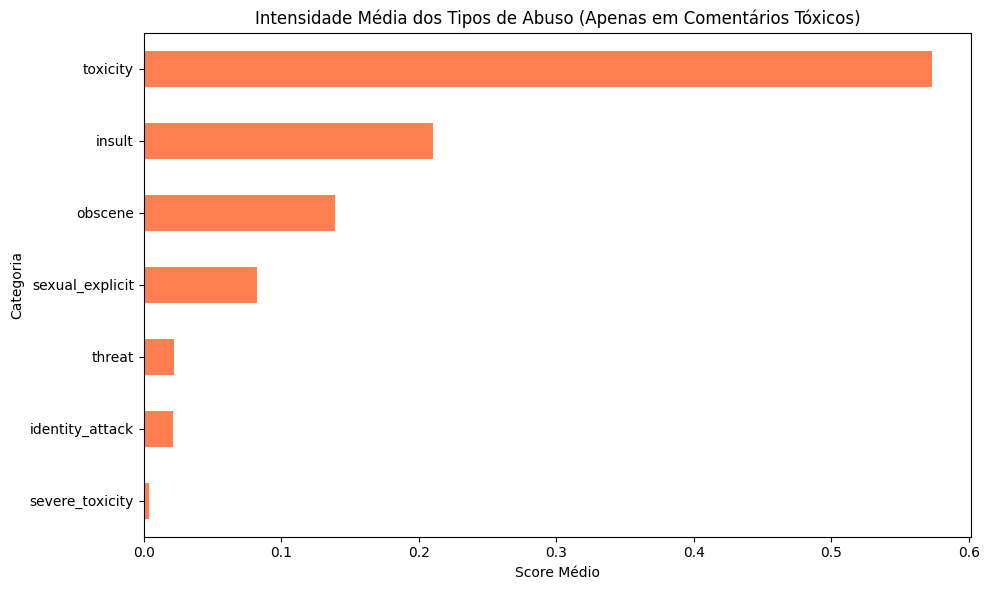

In [ ]:
# Instalação da biblioteca
!pip install detoxify -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from detoxify import Detoxify
from tqdm import tqdm
from google.colab import drive

# 1. Montar o drive (necessário se for executar a célula isoladamente após reiniciar a sessão)
drive.mount('/content/drive')

# 2. Caminho do dataset gerado nas etapas anteriores
PASTA_DRIVE = '/content/drive/MyDrive'
caminho_dataset_toxicidade = f'{PASTA_DRIVE}/dataset_reddit_com_toxicidade.csv'

# 3. Carregar o CSV para a variável 'df' antes de manipular
df = pd.read_csv(caminho_dataset_toxicidade)

# Definição de limiar de toxicidade
LIMIAR = 0.1
df['is_toxic'] = df['toxicity'] >= LIMIAR

total_comentarios = len(df)
total_toxicos = df['is_toxic'].sum()
total_nao_toxicos = total_comentarios - total_toxicos

perc_toxicos = (total_toxicos / total_comentarios) * 100
perc_nao_toxicos = (total_nao_toxicos / total_comentarios) * 100

print("\n" + "="*50)
print("ESTATÍSTICAS DESCRITIVAS DE TOXICIDADE")
print("="*50)
print(f"Total de comentários avaliados: {total_comentarios}")
print(f"% de Tóxicos: {perc_toxicos:.2f}% ({total_toxicos} comentários)")
print(f"% de Não Tóxicos: {perc_nao_toxicos:.2f}% ({total_nao_toxicos} comentários)")

# Tipos de toxicidade predominantes
categorias_toxicidade = ['toxicity', 'severe_toxicity', 'obscene', 'identity_attack', 'insult', 'threat', 'sexual_explicit']
print("\nMédia de pontuação por tipo de toxicidade (0 a 1):")
medias_tipos = df[categorias_toxicidade].mean().sort_values(ascending=False)
for categoria, media in medias_tipos.items():
    print(f"- {categoria}: {media:.4f}")

# Análise do top 10 autores
# Remover autores deletados para não enviesar a métrica
df_autores_validos = df[~df['author'].isin(['[Deletado/Anonimo]', '[deleted]'])]

# Agrupar por autor e contar número de comentários tóxicos
autores_toxicos = df_autores_validos[df_autores_validos['is_toxic']].groupby('author').size().reset_index(name='qtd_toxicos')
autores_toxicos = autores_toxicos.sort_values(by='qtd_toxicos', ascending=False)

top_10_autores = autores_toxicos.head(10)
total_toxicos_top_10 = top_10_autores['qtd_toxicos'].sum()

# Considerando apenas a rede de autores válidos para o cálculo da proporção
total_toxicos_rede_valida = df_autores_validos['is_toxic'].sum()
perc_representacao_top10 = (total_toxicos_top_10 / total_toxicos_rede_valida) * 100

print("\n" + "="*50)
print("TOP-10 AUTORES MAIS TÓXICOS")
print("="*50)
print(top_10_autores.to_string(index=False))
print(f"\nOs 10 autores mais tóxicos representam {perc_representacao_top10:.2f}% de todos os comentários tóxicos da rede.")

# Visualização da distribuição dos tipos de toxicidade nos comentários classificados como tóxicos
tipos_em_toxicos = df[df['is_toxic']][categorias_toxicidade].mean().sort_values()

plt.figure(figsize=(10, 6))
tipos_em_toxicos.plot(kind='barh', color='coral')
plt.title('Intensidade Média dos Tipos de Abuso (Apenas em Comentários Tóxicos)')
plt.xlabel('Score Médio')
plt.ylabel('Categoria')
plt.tight_layout()
plt.show()

=== TOP 10 BOLHAS (CLUSTERS) MAIS TÓXICAS ===
 cluster                                  Name  total_comentarios  perc_toxicidade
     414 414_áfrica_africa_africanos_religiões                 12        75.000000
     268          268_cadê_aconteceu_onde_what                 33        51.515152
     153           153_gado_vacas_vaca_cabeças                105        48.571429
      91        91_tigrinho_tiger_tigre_little                125        47.200000
     468           468_pneu_pneus_roda_volante               4836        41.542597
      19             19_nunca_sabia_ninguém_vi                 17        41.176471
     422        422_bullying_bully_sofrer_2030                210        37.619048
     350    350_speed_velocidade_speedrun_need                 22        31.818182
     351  351_eleito_reeleger_eleição_eleições                704        31.392045
      77           77_pior_piores_piorar_piora                745        29.664430

RESUMO DE COMENTÁRIOS POR AUTOR TOP-10



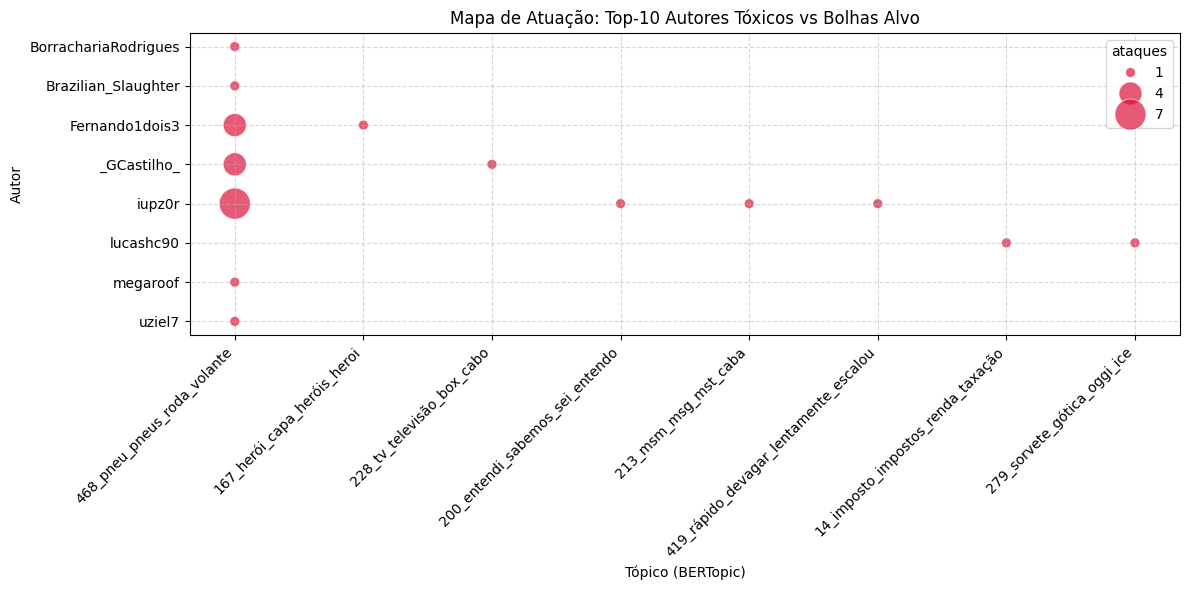


Dataset cruzado salvo em: /content/drive/MyDrive/dataset_cruzado_bolhas_toxicidade.csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

LIMIAR= 0.1

# redefinição de caminhos. Vou corrigir essa funcionalidade que tá sendo repetida em toda célula
# serve pra quando vou rodar determinada celula individualmente
PASTA_DRIVE = '/content/drive/MyDrive'
caminho_tox = f'{PASTA_DRIVE}/dataset_reddit_com_toxicidade.csv'
caminho_clusters = f'{PASTA_DRIVE}/clusters.csv'
caminho_topicos = f'{PASTA_DRIVE}/topicos_bertopic.csv'

df_tox = pd.read_csv(caminho_tox)

# filtro apenas as linhas que já foram processadas (que não são nulas na coluna 'toxicity')
# e criar a coluna 'is_toxic' baseada no limiar de 0.1 validado na literatura (SERÁ ALTERADO POIS
# VALOR ESTÁ MUITO SENSÍVEL)
df_tox_valido = df_tox[df_tox['toxicity'].notna()].copy()
df_tox_valido['is_toxic'] = df_tox_valido['toxicity'] >= LIMIAR

df_clusters = pd.read_csv(caminho_clusters)
df_topicos = pd.read_csv(caminho_topicos)

# mesclagem dos datasets (amostra de Toxicidade + clusters + nomes dos tópicos)
df_completo = pd.merge(df_tox_valido, df_clusters, on='comment_id', how='inner')
df_completo = pd.merge(df_completo, df_topicos[['Topic', 'Name']], left_on='cluster', right_on='Topic', how='left')

# análise de Bolhas Tóxicas (Proporção de toxicidade por cluster)
bolhas_stats = df_completo.groupby(['cluster', 'Name']).agg(
    total_comentarios=('comment_id', 'count'),
    total_toxicos=('is_toxic', 'sum')
).reset_index()

bolhas_stats['perc_toxicidade'] = (bolhas_stats['total_toxicos'] / bolhas_stats['total_comentarios']) * 100

# filtro de relevância (mínimo de 10 comentários) para ranquear as bolhas mais tóxicas
bolhas_relevantes = bolhas_stats[bolhas_stats['total_comentarios'] >= 10]
bolhas_mais_toxicas = bolhas_relevantes.sort_values(by='perc_toxicidade', ascending=False).head(10)

print("=== TOP 10 BOLHAS (CLUSTERS) MAIS TÓXICAS ===")
print(bolhas_mais_toxicas[['cluster', 'Name', 'total_comentarios', 'perc_toxicidade']].to_string(index=False))

# top-10 Autores na Rede
df_autores_validos = df_completo[~df_completo['author'].isin(['[Deletado/Anonimo]', '[deleted]'])]
top_10_autores = df_autores_validos[df_autores_validos['is_toxic']].groupby('author').size().nlargest(10).index.tolist()

df_top_autores = df_completo[df_completo['author'].isin(top_10_autores) & df_completo['is_toxic']]

# a fim de verificar, checando os comentários dos autores do top10
print("\n" + "="*50)
print("RESUMO DE COMENTÁRIOS POR AUTOR TOP-10")
print("="*50)

comentarios_por_autor = {}

for autor in top_10_autores:
    # filtra os comentários tóxicos apenas desse autor
    comentarios = df_top_autores[df_top_autores['author'] == autor]['text'].tolist()
    comentarios_por_autor[autor] = comentarios

    print(f"\nAutor: {autor}")
    print(f"Total de comentários tóxicos na amostra: {len(comentarios)}")
    print("Exemplos de comentários:")
    # imprime até os 3 primeiros comentários como exemplo
    for i, comentario in enumerate(comentarios[:3]):
        print(f"  {i+1}. {comentario}")

atuacao_autores = df_top_autores.groupby('author').agg(
    clusters_diferentes=('cluster', 'nunique'),
    total_ataques=('comment_id', 'count')
).reset_index().sort_values(by='total_ataques', ascending=False)

print("\n=== PERFIL DE ESPALHAMENTO DOS TOP-10 AUTORES ===")
print(atuacao_autores.to_string(index=False))

# rastreio da ação desses autores
plt.figure(figsize=(12, 6))
top_interacoes = df_top_autores.groupby(['author', 'Name']).size().reset_index(name='ataques')
clusters_alvo = top_interacoes.groupby('Name')['ataques'].sum().nlargest(8).index
dados_plot = top_interacoes[top_interacoes['Name'].isin(clusters_alvo)]

sns.scatterplot(data=dados_plot, x='Name', y='author', size='ataques', sizes=(50, 500), color='crimson', alpha=0.7)
plt.title('Mapa de Atuação: Top-10 Autores Tóxicos vs Bolhas Alvo')
plt.xlabel('Tópico (BERTopic)')
plt.ylabel('Autor')
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 6. Salvar o dataset consolidado
caminho_final = f'{PASTA_DRIVE}/dataset_cruzado_bolhas_toxicidade.csv'
df_completo.to_csv(caminho_final, index=False)
print(f"\nDataset cruzado salvo em: {caminho_final}")

In [ ]:
INVALIDOS = ['[Deletado/Anonimo]', '[deleted]', 'AutoModerator']

# base inteira: todos os comentários com toxicidade calculada
base_total = df_tox_valido[~df_tox_valido['author'].isin(INVALIDOS)]
tot_a = base_total['author'].nunique()
tox_a = base_total.loc[base_total['is_toxic'], 'author'].nunique()

# somente comentários que entraram na rede de usuários (pertencem a algum cluster)
base_rede = df_completo[~df_completo['author'].isin(INVALIDOS)]
tot_b = base_rede['author'].nunique()
tox_b = base_rede.loc[base_rede['is_toxic'], 'author'].nunique()

print("=" * 60)
print(f"DIMENSÃO POPULACIONAL DA TOXICIDADE (limiar = {LIMIAR})")
print("=" * 60)
print(f"Base inteira: {tot_a} autores | {tox_a} com ≥1 comentário tóxico "
      f"({100 * tox_a / tot_a:.2f}%)")
print(f"Dentro da rede: {tot_b} autores | {tox_b} com ≥1 comentário tóxico "
      f"({100 * tox_b / tot_b:.2f}%)")
print("Obs.: numerador e denominador usam sempre a MESMA base em cada linha.")

DIMENSÃO POPULACIONAL DA TOXICIDADE (limiar = 0.1)
Base inteira: 58082 autores | 26374 com ≥1 comentário tóxico (45.41%)
Dentro da rede: 42941 autores | 19225 com ≥1 comentário tóxico (44.77%)
Obs.: numerador e denominador usam sempre a MESMA base em cada linha.


### Criação de Rede de Co-Commenters

Foi realizada o mapeamento e a conexão dos usuários entre si (co-commenters). O mapeamento foi realizado em cima do dataset finalizado, com a análise da toxicidade já realizada. A partir do dataset limpo, removemos autores inválidos (contas apagadas ou bots moderadores). Em seguida, agrupámos os dados pela chave post_id (a thread de discussão).
Utilizando a biblioteca networkx, criámos um Grafo Não-Direcionado (nx.Graph()). A lógica de formação de arestas foi: sempre que dois utilizadores (nós) publicam comentários na mesma thread, estabelece-se uma aresta entre eles. O peso da aresta (weight) aumenta sempre que esta interação se repete em outras threads.
Utilizamos unique() na coleta para previnir que não fossem criadas arestas de conexão do autor consigo mesmo


In [ ]:
#rede de co-commenters
import networkx as nx
from networkx.algorithms.community import louvain_communities
from itertools import combinations
import pickle

print("Construindo a rede de usuários (Co-commenters)...")

# remoção de moderadores ou comentários cujo autor é anonimo ou deletado. Essa parte já foi realizada em pré processamento, porém reforçando
autores_invalidos = ['[Deletado/Anonimo]', '[deleted]', 'AutoModerator']
df_autores = df_completo[~df_completo['author'].isin(autores_invalidos)].copy()

# inicializa o grafo não-direcionado
G_users = nx.Graph()

# agrupa autores por thread (post_id)
# usei unique() pra evitar que um mesmo autor seja ligado a ele mesmo
autores_por_thread = df_autores.groupby('post_id')['author'].unique()

# cria as arestas (interações cruzadas na mesma thread indicam a bolha)
for autores in autores_por_thread:
    if len(autores) > 1:
        for u1, u2 in combinations(autores, 2):
            if G_users.has_edge(u1, u2):
                G_users[u1][u2]['weight'] += 1
            else:
                G_users.add_edge(u1, u2, weight=1)

print(f"Rede construída: {G_users.number_of_nodes()} usuários (nós) e {G_users.number_of_edges()} conexões (arestas).")

# detecção de comunidades para mapear as panelinhas
comunidades_usuarios = louvain_communities(G_users, weight='weight', resolution=1.0, seed=42)
print(f"Total de bolhas sociais identificadas: {len(comunidades_usuarios)}")

# Exportação do grafo para análises futuras ou plotagem no Gephi
caminho_rede_users = f'{PASTA_DRIVE}/rede_co_commenters.pkl'
with open(caminho_rede_users, 'wb') as f:
    pickle.dump(G_users, f)
print(f"Rede salva em: {caminho_rede_users}")

Construindo a rede de usuários (Co-commenters)...
Rede construída: 42941 usuários (nós) e 6963508 conexões (arestas).
Total de bolhas sociais identificadas: 10
Rede salva em: /content/drive/MyDrive/rede_co_commenters.pkl


In [ ]:
caminho_rede_users = f'{PASTA_DRIVE}/rede_co_commenters.pkl'
autores_invalidos = ['[Deletado/Anonimo]', '[deleted]', 'AutoModerator']
df_autores = df_completo[~df_completo['author'].isin(autores_invalidos)].copy()

In [ ]:
df_autores = df_completo[~df_completo['author'].isin(autores_invalidos)].copy()

### Extração psicolinguistíca

Utilizei inicialmente o EmoLex pois o LIWIC descobri que (pelo menos atualmente) é pago para ter acesso ao dicionário, portanto não foi possível a utilização. Já solicitei à um professor que realizou a adaptação do LIWIC e criou uma versão para português, porém ainda não recebi.





In [ ]:
# Instalação do parser do LIWC no Colab
!pip install liwc -q

import liwc
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

print("Carregando o dicionário LIWC...")

#definição do caminho do liwic
caminho_dicionario = '/content/drive/MyDrive/Brazilian_Portuguese_LIWC2015_dictionary.dic'

# o omando load_token_parser interpreta a estrutura proprietária do LIWC
parse, category_names = liwc.load_token_parser(caminho_dicionario)

def analisar_liwc(texto):
    """Quebra o texto em tokens minúsculos e extrai as frequências de cada categoria do LIWC."""
    tokens = re.findall(r'\b\w+\b', str(texto).lower())

    # O token verifica a qual categoria o token pertence dentro do LIWC
    contagem = Counter(category for token in tokens for category in parse(token))
    return dict(contagem)

print("Extraindo features psicolinguísticas dos comentários com o LIWC...")

#aplicando aos dados
df_completo['liwc_features'] = df_completo['text'].apply(analisar_liwc)


# Expande o dicionário gerado em colunas separadas para cada categoria e preenche vazios com 0
df_liwc_expandido = df_completo['liwc_features'].apply(pd.Series).fillna(0)

# Une os resultados ao DataFrame principal contendo a coluna 'is_toxic'
df_analise_liwc = pd.concat([df_completo[['is_toxic']], df_liwc_expandido], axis=1)

# Categorias de foco mapeadas pela literatura de referência:
categorias_foco = ['posemo', 'negemo', 'anger', 'anx', 'sad', 'swear', 'body', 'sexual', 'family', 'power', 'risk', 'money', 'relig', 'death']

# Filtra apenas as colunas que realmente apareceram nos seus textos
cols_disponiveis = [col for col in categorias_foco if col in df_analise_liwc.columns]

# Agrupa para descobrir as médias de uso: Tóxicos vs Não Tóxicos
comparativo_liwc = df_analise_liwc.groupby('is_toxic')[cols_disponiveis].mean().T
comparativo_liwc.columns = ['Nao_Toxico', 'Toxico']

# Calcula a Diferença Absoluta para elencar quais categorias destacam mais a agressão
comparativo_liwc['Diferenca_Absoluta'] = comparativo_liwc['Toxico'] - comparativo_liwc['Nao_Toxico']
comparativo_liwc = comparativo_liwc.sort_values(by='Diferenca_Absoluta', ascending=False)

print("\n PERFIL PSICOLINGUÍSTICO LIWC (TÓXICOS VS NÃO TÓXICOS)")
print(comparativo_liwc)

#plotagem
print("\nGerando gráfico comparativo...")
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")

#derrete a tabela (usando .melt) para o formato exigido pelo Seaborn para plotar barras agrupadas
df_plot = comparativo_liwc.reset_index().rename(columns={'index': 'Categoria LIWC'})
df_plot = df_plot.melt(id_vars='Categoria LIWC', value_vars=['Toxico', 'Nao_Toxico'],
                       var_name='Classe', value_name='Média de Ocorrências')

# Substitui as flags por nomenclaturas legíveis para a legenda do gráfico
df_plot['Classe'] = df_plot['Classe'].replace({'Toxico': 'Tóxico', 'Nao_Toxico': 'Não Tóxico'})

# Plota o gráfico de barras horizontais
ax = sns.barplot(data=df_plot, y='Categoria LIWC', x='Média de Ocorrências', hue='Classe', palette=['crimson', 'steelblue'])

plt.title('Comparativo Psicolinguístico (LIWC): Comentários Tóxicos vs Não Tóxicos', fontsize=14, pad=15)
plt.xlabel('Média de Ocorrências por Comentário', fontsize=12)
plt.ylabel('Categoria Lexical (LIWC)', fontsize=12)
plt.legend(title='Classificação do Comentário')
plt.tight_layout()

#salvamento da figura
caminho_figura = '/content/drive/MyDrive/grafico_liwc.png'
plt.savefig(caminho_figura, dpi=300)
plt.show()

print(f"Gráfico salvo com sucesso em: {caminho_figura}")

In [ ]:
PASTA_DRIVE = '/content/drive/MyDrive'
caminho_tox = f'{PASTA_DRIVE}/dataset_reddit_com_toxicidade.csv'
caminho_clusters = f'{PASTA_DRIVE}/clusters.csv'
caminho_topicos = f'{PASTA_DRIVE}/topicos_bertopic.csv'
df_tox = pd.read_csv(caminho_tox)
LIMIAR = 0.1

df_tox_valido = df_tox[df_tox['toxicity'].notna()].copy()
df_tox_valido['is_toxic'] = df_tox_valido['toxicity'] >= LIMIAR

In [ ]:
import pickle
from networkx.algorithms.community import louvain_communities


PASTA_DRIVE = '/content/drive/MyDrive'
caminho_rede_users = f'{PASTA_DRIVE}/rede_co_commenters.pkl'


print("Carregando a rede de co-commenters do Drive...")
with open(caminho_rede_users, 'rb') as f:
    G_users = pickle.load(f)

print(f"Rede carregada com sucesso: {G_users.number_of_nodes()} usuários e {G_users.number_of_edges()} arestas.")

#
print("Recalculando as bolhas sociais (Louvain)...")
comunidades_usuarios = louvain_communities(G_users, weight='weight', resolution=1.0, seed=42)

print(f"Total de bolhas sociais identificadas: {len(comunidades_usuarios)}")

Carregando a rede de co-commenters do Drive...
Rede carregada com sucesso: 42941 usuários e 6963508 arestas.
Recalculando as bolhas sociais (Louvain)...
Total de bolhas sociais identificadas: 10


In [ ]:
import pandas as pd

# mapeandoo cada usuário para o ID da sua bolha social
user_to_bubble = {}
for bubble_id, users in enumerate(comunidades_usuarios):
    for user in users:
        user_to_bubble[user] = bubble_id

# criando um DF de bolhas e mesclar com os autores válidos
df_bubbles = pd.DataFrame(list(user_to_bubble.items()), columns=['author', 'social_bubble'])
df_autores_bolhas = pd.merge(df_autores_validos, df_bubbles, on='author', how='inner')

# calculando as estatísticas de toxicidade por bolha
bolhas_sociais_stats = df_autores_bolhas.groupby('social_bubble').agg(
    total_usuarios=('author', 'nunique'),
    total_comentarios=('comment_id', 'count'),
    total_toxicos=('is_toxic', 'sum')
).reset_index()

#descobrindo o percentual de toxicidade de cada bolha
bolhas_sociais_stats['perc_toxicidade'] = (bolhas_sociais_stats['total_toxicos'] / bolhas_sociais_stats['total_comentarios']) * 100

print(" BOLHAS SOCIAIS MAIS TÓXICAS")
print(bolhas_sociais_stats.sort_values('perc_toxicidade', ascending=False).head(10))

In [ ]:
import networkx as nx

print("Calculando métricas de centralidade")

# grau de conexão de cada usuário
degree_dict = nx.degree_centrality(G_users)

# capacidade de ser ligação entre diferentes grupos
betweenness_dict = nx.betweenness_centrality(G_users, k=1000, seed=42)

# cria DF com as métricas da rede
nx_metrics_df = pd.DataFrame({
    'author': list(degree_dict.keys()),
    'degree': list(degree_dict.values()),
    'betweenness': list(betweenness_dict.values())
})

# cruza as métricas de rede com a proporção de toxicidade de cada autor
taxa_tox_autor = df_autores_bolhas.groupby('author')['is_toxic'].mean().reset_index()
broadcasters_df = pd.merge(nx_metrics_df, taxa_tox_autor, on='author')

print("=== MAIORES ESPALHADORES (PONTES ENTRE BOLHAS) ===")
print(broadcasters_df.sort_values('betweenness', ascending=False).head(10))

Calculando métricas de centralidade
=== MAIORES ESPALHADORES (PONTES ENTRE BOLHAS) ===
                     author    degree  betweenness  is_toxic
363                  iupz0r  0.242175     0.038066  0.317365
78                SaveVideo  0.106730     0.023113  0.000000
3024             brunomocsa  0.086959     0.010003  0.223529
4588                Lancone  0.150303     0.008858  0.348837
11269   BreakfastSecure6504  0.129623     0.008738  0.303797
18     Prudent_Disaster_984  0.092012     0.007759  0.440000
16046     Little_Blackberry  0.058780     0.005578  0.234043
490           Adrianwill-87  0.097951     0.005517  0.250000
1025                 uziel7  0.061504     0.005474  0.209581
26570           ehmuidifici  0.054495     0.005423  0.300000


In [ ]:
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from networkx.algorithms.community import louvain_communities
sns.set_theme(style="whitegrid")

#  quantos pares comentam juntos em mais de uma thread?
n_arestas = G_users.number_of_edges()
cont = Counter(min(d['weight'], 6) for _, _, d in G_users.edges(data=True))
print("Pares de usuários por nº de threads em comum:")
for k in sorted(cont):
    rotulo = '6+' if k == 6 else str(k)
    print(f"  {rotulo:>2} thread(s): {cont[k]:>10,}  ({100 * cont[k] / n_arestas:5.1f}%)".replace(',', '.'))

#  rede de recorrentes: só pares com ≥ MIN_THREADS_COMUNS threads em comum
MIN_THREADS_COMUNS = 2
arestas_rec = [(u, v) for u, v, d in G_users.edges(data=True) if d['weight'] >= MIN_THREADS_COMUNS]
G_rec = G_users.edge_subgraph(arestas_rec).copy()
maior = max(nx.connected_components(G_rec), key=len)
print(f"\nRede de recorrentes (≥{MIN_THREADS_COMUNS} threads): {G_rec.number_of_nodes()} usuários "
      f"({100 * G_rec.number_of_nodes() / G_users.number_of_nodes():.1f}% da rede), "
      f"{G_rec.number_of_edges()} arestas, densidade {nx.density(G_rec):.5f}")
print(f"Componentes: {nx.number_connected_components(G_rec)} | "
      f"maior componente: {100 * len(maior) / G_rec.number_of_nodes():.1f}% dos nós")

com_rec = louvain_communities(G_rec, weight='weight', resolution=1.0, seed=42)
mapa_rec = {u: i for i, c in enumerate(com_rec) for u in c}
print(f"Comunidades na rede de recorrentes: {len(com_rec)} | "
      f"modularidade: {nx.community.modularity(G_rec, com_rec, weight='weight'):.3f}")

# toxicidade por comunidade recorrente (só comunidades com ≥50 usuários)
d = df_autores.copy()
d['bolha_rec'] = d['author'].map(mapa_rec)
d = d.dropna(subset=['bolha_rec']).copy()
d['bolha_rec'] = d['bolha_rec'].astype(int)
stats_rec = (d.groupby('bolha_rec')
             .agg(usuarios=('author', 'nunique'), comentarios=('comment_id', 'count'),
                  perc_toxico=('is_toxic', 'mean')))
stats_rec['perc_toxico'] *= 100
grandes_rec = stats_rec[stats_rec['usuarios'] >= 50].sort_values('usuarios', ascending=False)
print("\nComunidades recorrentes com ≥50 usuários:")
print(grandes_rec.round(1))

#  comunidades × subreddit (as bolhas são só os subreddits?)
ct_orig = (pd.crosstab(df_autores_bolhas['social_bubble'], df_autores_bolhas['subreddit'],
                       normalize='index') * 100)
dg = d[d['bolha_rec'].isin(grandes_rec.index)]
ct_rec = pd.crosstab(dg['bolha_rec'], dg['subreddit'], normalize='index') * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 5),
                       gridspec_kw={'width_ratios': [1, max(0.4, len(ct_rec) / max(len(ct_orig), 1))]})
sns.heatmap(ct_orig, annot=True, fmt='.0f', cmap='Blues', ax=ax[0], cbar=False)
ax[0].set_title('Bolhas da rede completa (Louvain)\n% dos comentários por subreddit')
sns.heatmap(ct_rec, annot=True, fmt='.0f', cmap='Blues', ax=ax[1],
            cbar_kws={'label': '% dos comentários'})
ax[1].set_title('Comunidades da rede de recorrentes (≥50 usuários)\n% dos comentários por subreddit')
plt.tight_layout()
plt.savefig(f'{PASTA_DRIVE}/grafico_bolhas_subreddit.png', dpi=200)
plt.show()


In [ ]:
print(df_autores_bolhas.columns)

In [ ]:
# filtrar o DataFrame apenas para os comentários do autor 'iupz0r'
comentarios_iupz0r = df_autores_bolhas[df_autores_bolhas['author'] == 'iupz0r']


print(f"Total de comentários encontrados no dataset: {len(comentarios_iupz0r)}")
print("="*60)

# imprime os 10 primeiros comentários dele para análise
for i, texto in enumerate(comentarios_iupz0r['text'].head(10)):
    print(f"Comentário {i+1}:")
    print(texto)
    print("-" * 60)

In [ ]:
# filtrar pelo autor E pela flag de toxicidade
toxicos_iupz0r = df_autores_bolhas[
    (df_autores_bolhas['author'] == 'iupz0r') &
    (df_autores_bolhas['is_toxic'] == 1)
]

print(f"Total de comentários tóxicos do iupz0r: {len(toxicos_iupz0r)}")
print("="*60)

# imprime os 10 primeiros comentários classificados como tóxicos
for i, texto in enumerate(toxicos_iupz0r['text'].head(1000)):
    print(f"Comentário Tóxico {i+1}:")
    print(texto)
    print("-" * 60)

In [ ]:
# Retorna o número de arestas (interações)
total_interacoes = G_users.degree('iupz0r')

# Retorna o número de vizinhos únicos (pessoas diferentes)
pessoas_unicas = len(list(G_users.neighbors('iupz0r')))

print(f"O iupz0r teve {total_interacoes} interações no total.")
print(f"Ele interagiu com {pessoas_unicas} usuários únicos.")